In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
import math

raw_matrix = np.array([[1,2,3,4,5],[6,7,8,9,10],[11,12,13,14,15]]) # WILL NEED TO CHANGE FOR OTHER MATRIXES
category_dict = {"Cardiovascular System":["Heart", "Atrium"], "Connective Tissue":["Adipose"]}
raw_categories = ["Heart", "Atrium", "Heart", "Adipose", "Adipose"]
gene_names = ["MYH1", "MYH2", "MYH3"]  # WILL NEED TO CHANGE FOR OTHER MATRIXES

# Master User Input Variables 

In [2]:
# Get the index of "MYH1" in the gene_names list
gene_name = "MYH1"
gene_index = gene_names.index(gene_name)


---
# RAW

In [3]:
# Extract the indexed row from the raw_matrix, WILL NEED TO CHANGE FOR OTHER MATRIXES
raw_gene_data = raw_matrix[gene_index]
print(raw_gene_data)

[1 2 3 4 5]


In [4]:
# Functions

def get_gene_category_averages(gene_data, category_dict, categories):
    result = {}
    for category, values in category_dict.items():
        matching_indices = [i for i, name in enumerate(categories) if name in values]
        category_values = gene_data[matching_indices]
        average_value = np.mean(category_values)
        result[category] = [average_value]

    return result

def convert_to_matrix(dictionary):
    values_array = np.array(list(dictionary.values()))
    return values_array.flatten()

def perform_ooe(gene_data, geneset_catAvg_matrix):
    # Calculate the average of geneset_catAvg_matrix
    avg = sum(geneset_catAvg_matrix) / len(geneset_catAvg_matrix)
    
     
    # Divide each element in raw_gene_data by the average
    ooe_values = [gene_value / avg for gene_value in raw_gene_data]
    
# OOE but with an additional log2 that I later realized is not needed (we already did log2 during QN processing)
#     # Divide each element in raw_gene_data by the average and apply log2
#     ooe_values = [math.log2(gene_value / avg) for gene_value in gene_data]
    
    return ooe_values

def get_gene_cat_matrix(data, category_dict, categories):
    result = []
    for category, values in category_dict.items():
        temp = []
        for value in values:
            temp.extend([data[i] for i, cat in enumerate(categories) if cat == value])
        result.append(temp)
    return result

def get_filtered_matrix_enrichment_values(raw_gene_data, category_dict, raw_categories):
    # Calculate Category RAW Matrix
    cat_RAW_matrix = get_gene_cat_matrix(raw_gene_data, category_dict, raw_categories)
    print("Category RAW Matrix")
    print(cat_RAW_matrix)
    print("------------------------\n")

    # Calculate Geneset Category Averages
    geneset_catAvg_dict = get_gene_category_averages(raw_gene_data, category_dict, raw_categories)
    print("Geneset Category Averaged - Dict Form:")
    print(geneset_catAvg_dict)
    print()

    geneset_catAvg_matrix = convert_to_matrix(geneset_catAvg_dict)
    print("Dict to Matrix")
    print(geneset_catAvg_matrix)
    print()

    # Perform OOE
    ooe_data = perform_ooe(raw_gene_data, geneset_catAvg_matrix)
    print("OOE Matrix")
    print(ooe_data)
    print()
    
    return ooe_data

ooe_data = get_filtered_matrix_enrichment_values(raw_gene_data, category_dict, raw_categories)

raw_cat_ooe_matrix = get_gene_cat_matrix(ooe_data, category_dict, raw_categories) # (aka: get_gene_cat_ooe_matrix)
print("Category OOE Matrix")
print(raw_cat_ooe_matrix)
print()


Category RAW Matrix
[[1, 3, 2], [4, 5]]
------------------------

Geneset Category Averaged - Dict Form:
{'Cardiovascular System': [2.0], 'Connective Tissue': [4.5]}

Dict to Matrix
[2.  4.5]

OOE Matrix
[0.3076923076923077, 0.6153846153846154, 0.9230769230769231, 1.2307692307692308, 1.5384615384615385]

Category OOE Matrix
[[0.3076923076923077, 0.9230769230769231, 0.6153846153846154], [1.2307692307692308, 1.5384615384615385]]



In [5]:
# IMPORTANT: xlabel list 
xlabel_system_names = ([key.replace(" System", "") for key in category_dict.keys()])

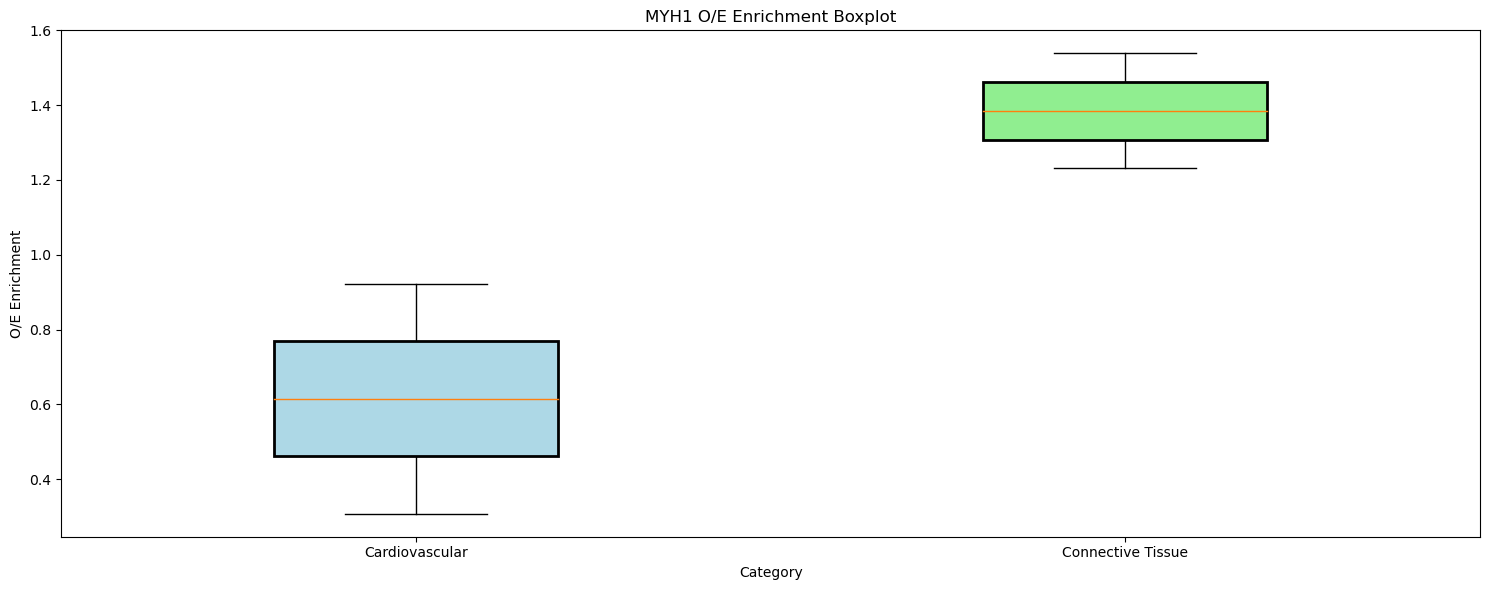

In [6]:
# Plot Indiv. Gene Data (ie. Raw)
def plot_individual_gene_data(matrix, gene_name):
    fig, ax = plt.subplots(figsize=(15, 6))

    positions = np.arange(len(matrix))
    boxprops = dict(linewidth=2)

    bp = ax.boxplot(matrix, positions=positions, widths=0.4, patch_artist=True, boxprops=boxprops)

    ax.set_xticks(positions)
    ax.set_xticklabels(xlabel_system_names)
    ax.set_xlabel("Category")
    ax.set_ylabel("O/E Enrichment")
    ax.set_title(f"{gene_name} O/E Enrichment Boxplot")

    colors = ["lightblue", "lightgreen", "moccasin", "pink"]
    for box, color in zip(bp["boxes"], colors):
        box.set_facecolor(color)

    plt.tight_layout()
    plt.show()
    
plot_individual_gene_data(raw_cat_ooe_matrix, gene_name)

---
# ALL 4 MATRIX BOXPLOT - ALL SYSTEMS

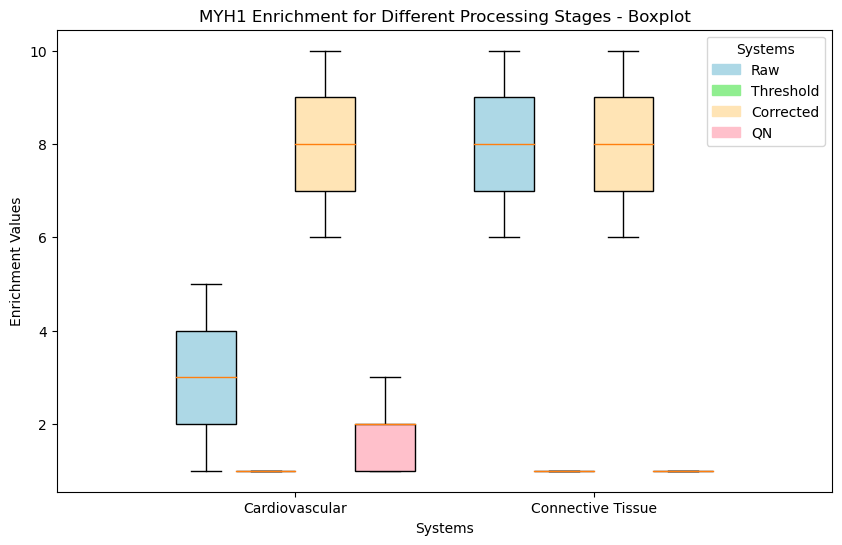

In [7]:
raw_matrix = [[1, 2, 3, 4, 5], [6, 7, 8, 9, 10]]
qn_matrix = [[1, 1, 2, 2, 3], [1, 1, 1, 1, 1]]
threshold_matrix = [[1, 1, 1, 1, 1], [1, 1, 1, 1, 1]]
corrected_matrix = [[10, 9, 8, 7, 6], [6, 7, 8, 9, 10]]
categories = ["Cardiovascular", "Connective Tissue"]
system_names = ["Raw", "Threshold", "Corrected", "QN"]
colors = ["lightblue", "lightgreen", "moccasin", "pink"]

def plot_all_systems_data(raw_matrix, qn_matrix, threshold_matrix, corrected_matrix, categories, system_names, colors):
    fig, ax = plt.subplots(figsize=(10, 6))

    # Iterate over each category and corresponding rows in the matrices
    for i, category in enumerate(categories):
        # Calculate the positions for the boxplots
        positions = [i - 0.3, i - 0.1, i + 0.1, i + 0.3]

        # Extract the values for the current category from the matrices
        raw_values = raw_matrix[i]
        threshold_values = threshold_matrix[i]
        corrected_values = corrected_matrix[i]
        qn_values = qn_matrix[i]

        # Plot the boxplots side by side
        boxplot = ax.boxplot(
            [raw_values, threshold_values, corrected_values, qn_values],
            positions=positions,
            widths=0.2,
            patch_artist=True,
        )

        # Set the facecolor for each boxplot
        for patch, color in zip(boxplot["boxes"], colors):
            patch.set_facecolor(color)

    # Create custom legend handles with associated colors
    legend_handles = [
        mpatches.Patch(color=color, label=system_name)
        for color, system_name in zip(colors, system_names)
    ]

    # Set the x-axis tick labels and title
    ax.set_xticks(range(len(categories)))
    ax.set_xticklabels(categories)
    ax.set_xlabel("Systems")

    # Set the y-axis label
    ax.set_ylabel("Enrichment Values")

    # Display the legend with custom handles and title
    ax.legend(handles=legend_handles, title="Systems")

    # Set the title
    plt.title(gene_name + " Enrichment for Different Processing Stages - Boxplot")

    # Show the plot
    plt.show()

# Call the function to plot the data
plot_all_systems_data(raw_matrix, qn_matrix, threshold_matrix, corrected_matrix, categories, system_names, colors)

---
# ALL 4 MATRIX BOXPLOT - CARDIOVASCULAR SYSTEM

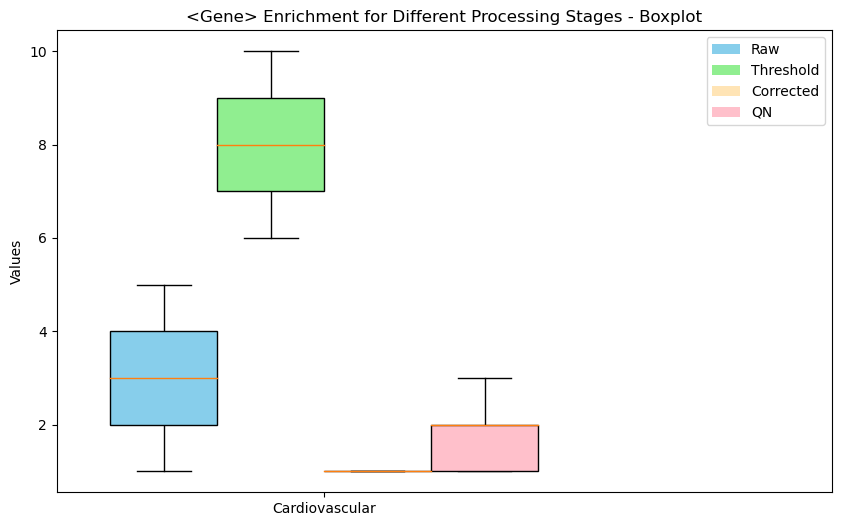

In [9]:
def plot_individual_system_data(raw_matrix, qn_matrix, threshold_matrix, corrected_matrix, category_dict):
    
    system_idx = 0 # MASTER USER INPUT
    
    # Extract the first category name and its corresponding values from the category_dict
    category = xlabel_system_names[system_idx]
    data = list(category_dict.values())[system_idx]

    # Extract the first row of the raw_matrix, qn_matrix, threshold_matrix, and corrected_matrix
    category_values_raw = raw_matrix[system_idx]
    category_values_qn = qn_matrix[system_idx]
    category_values_threshold = threshold_matrix[system_idx]
    category_values_corrected = corrected_matrix[system_idx]

    # Set the figure size (increase the width as desired)
    fig, ax = plt.subplots(figsize=(10, 6))

    # Set the width for each boxplot
    width = 0.4

    # Set the positions for the boxplots
    positions_raw = np.array([0])
    positions_threshold = positions_raw + width
    positions_corrected = positions_threshold + width
    positions_qn = positions_corrected + width
    
    # Plot a boxplot for the first category values from raw_matrix
    ax.boxplot(category_values_raw, positions=positions_raw, labels=[category],
               patch_artist=True, boxprops=dict(facecolor='skyblue'), widths=width)

    # Plot a boxplot for the first category values from threshold_matrix
    ax.boxplot(category_values_threshold, positions=positions_threshold, labels=[''],
               patch_artist=True, boxprops=dict(facecolor='lightgreen'), widths=width)

    # Plot a boxplot for the first category values from corrected_matrix
    ax.boxplot(category_values_corrected, positions=positions_corrected, labels=[''],
               patch_artist=True, boxprops=dict(facecolor='moccasin'), widths=width)
    
 # Plot a boxplot for the first category values from qn_matrix
    ax.boxplot(category_values_qn, positions=positions_qn, labels=[''],
               patch_artist=True, boxprops=dict(facecolor='pink'), widths=width)
    
    # Set the x-axis limits
    ax.set_xlim(-width, 2.5)

    # Set the x-axis tick positions and labels
    tick_positions = np.array([width * 1.5])  # Adjust the position for centering
    tick_labels = [category]
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels, ha='center')  # Set horizontal alignment to center

    # Set the y-axis label
    ax.set_ylabel('Values')

    # Set the title
    ax.set_title('<Gene> Enrichment for Different Processing Stages - Boxplot')

    # Create custom legend labels for the boxplot colors
    blue_patch = plt.Rectangle((0, 0), 1, 1, fc='skyblue')
    green_patch = plt.Rectangle((0, 0), 1, 1, fc='lightgreen')
    orange_patch = plt.Rectangle((0, 0), 1, 1, fc='moccasin')
    pink_patch = plt.Rectangle((0, 0), 1, 1, fc='pink')
    ax.legend([blue_patch, green_patch, orange_patch, pink_patch], ['Raw',  'Threshold', 'Corrected','QN'])

    # Display the plot
    plt.show()

# Example usage
raw_matrix = [[1,2,3,4,5],[6,7,8,9,10]]
threshold_matrix = [[10,9,8,7,6],[6,7,8,9,10]]
corrected_matrix = [[1,1,1,1,1],[1,1,1,1,1]]
qn_matrix = [[1,1,2,2,3],[1,1,1,1,1]]
category_dict = {"Cardiovascular System": ["Heart", "Atrium"], "Connective Tissue": ["Adipose"]}

plot_individual_system_data(raw_matrix, qn_matrix, threshold_matrix, corrected_matrix, category_dict)
